<a href="https://colab.research.google.com/github/deividsantosjorge-dev/Economista_codando/blob/main/Limite_Credito_Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Este projeto dá continuidade ao modelo de classificação de inadimplência desenvolvido anteriormente com uma única Árvore de Decisão.
Nesta etapa, será utilizado o modelo bagging com o algoritmo Random Forest para avaliar se a combinação de múltiplas árvores melhora a capacidade de generalização e a classificação dos clientes.

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split,StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay,
    make_scorer,
)

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/deividsantosjorge-dev/DataSet---ML/refs/heads/main/credito.csv')

In [ ]:
pd.set_option('display.max_columns', None)
print(df.head())

          id  default  idade sexo  dependentes         escolaridade  \
0  768805383        0     45    M            3         ensino medio   
1  818770008        0     49    F            5             mestrado   
2  713982108        0     51    M            3             mestrado   
3  769911858        0     40    F            4         ensino medio   
4  709106358        0     40    M            3  sem educacao formal   

  estado_civil   salario_anual tipo_cartao  meses_de_relacionamento  \
0       casado     $60K - $80K        blue                       39   
1     solteiro  menos que $40K        blue                       44   
2       casado    $80K - $120K        blue                       36   
3           na  menos que $40K        blue                       34   
4       casado     $60K - $80K        blue                       21   

   qtd_produtos  iteracoes_12m  meses_inativo_12m limite_credito  \
0             5              3                  1      12.691,51   
1         

In [ ]:
df.shape

(10127, 16)

In [ ]:
#Antes de rodar qualquer modelo, precisamos primeiro averiguar nossos dados.
#Nenhuma coluna com dados nulos

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   id                       10127 non-null  int64 
 1   default                  10127 non-null  int64 
 2   idade                    10127 non-null  int64 
 3   sexo                     10127 non-null  object
 4   dependentes              10127 non-null  int64 
 5   escolaridade             10127 non-null  object
 6   estado_civil             10127 non-null  object
 7   salario_anual            10127 non-null  object
 8   tipo_cartao              10127 non-null  object
 9   meses_de_relacionamento  10127 non-null  int64 
 10  qtd_produtos             10127 non-null  int64 
 11  iteracoes_12m            10127 non-null  int64 
 12  meses_inativo_12m        10127 non-null  int64 
 13  limite_credito           10127 non-null  object
 14  valor_transacoes_12m     10127 non-nul

In [ ]:
#Verifico as colunas que estão como objetos para ver se alguma precisa ser aplicada One-Hot Encoding. Há também o caso de que algumas estã sendo tratadas como texto sendo que são numeros
df.select_dtypes(include='object').head()

,sexo,escolaridade,estado_civil,salario_anual,tipo_cartao,limite_credito,valor_transacoes_12m
0,M,ensino medio,casado,$60K - $80K,blue,"12.691,51","1.144,90"
1,F,mestrado,solteiro,menos que $40K,blue,"8.256,96","1.291,45"
2,M,mestrado,casado,$80K - $120K,blue,"3.418,56","1.887,72"
3,F,ensino medio,na,menos que $40K,blue,"3.313,03","1.171,56"
4,M,sem educacao formal,casado,$60K - $80K,blue,"4.716,22","816,08"


In [ ]:
#Percebi que limite de credito e valor_transacoes estavam sendo armazenados como texto, isso pq o Pandas reconhece numero no formato 'xxxx.xx'.
#Então, meu passo é transformá-los em numero.
colunas = ['limite_credito', 'valor_transacoes_12m']


In [ ]:
#Aqui eu tiro os pontos e converto virgulas por pontos usando a função for
for coluna in colunas:
  df[coluna]=df[coluna].str.replace('.','',regex=False)
  df[coluna]=df[coluna].str.replace(',','.',regex=False)



In [ ]:
#ok, deu certo
df[colunas].head()

,limite_credito,valor_transacoes_12m
0,12691.51,1144.90
1,8256.96,1291.45
2,3418.56,1887.72
3,3313.03,1171.56
4,4716.22,816.08


In [ ]:
#No entanto, verifiquei que ainda estão sendo armazenados como object
df[colunas].dtypes

,0
limite_credito,object
valor_transacoes_12m,object


In [ ]:
#peço para transformar em float. Perceba que se eu tivesse rodado desde o inicio essa função abaixo, ele não iria transformar os dados
#em float, pq o python não reconhece esse formato 'x.xxx,xx'
for coluna in colunas:
  df[coluna]=df[coluna].astype(float)

In [ ]:
#Ok, trabalho feito para limite_credito e valor transacoes
df[colunas].dtypes

,0
limite_credito,float64
valor_transacoes_12m,float64


In [ ]:
#Para as demais colunas objetos, vamos verificar como se comporta as categorias delas e aplicar One-Hot Encoding se for o caso
for coluna in ['sexo', 'escolaridade', 'estado_civil', 'salario_anual', 'tipo_cartao']:
    print(coluna)
    print(df[coluna].unique())

sexo
['M' 'F']
escolaridade
['ensino medio' 'mestrado' 'sem educacao formal' 'na' 'graduacao'
 'doutorado']
estado_civil
['casado' 'solteiro' 'na' 'divorciado']
salario_anual
['$60K - $80K' 'menos que $40K' '$80K - $120K' '$40K - $60K' '$120K +'
 'na']
tipo_cartao
['blue' 'gold' 'silver' 'platinum']


In [ ]:
#Encontrei que havia um problema maior, que era a ausencia de dados, representados por 'na'. Resolvi contabilizar quantos na tenho
for coluna in ['sexo', 'escolaridade', 'estado_civil', 'salario_anual', 'tipo_cartao']:
  print(coluna, (df[coluna]=='na').sum())

sexo 0
escolaridade 1519
estado_civil 749
salario_anual 1112
tipo_cartao 0


In [ ]:
#Tomei a decisão de excluir as linhas que possuem 'na'.
#Uma decisão diferente seria substitui-las pela categoria mais frequente de cada variavel (para essa alternativa, vou deixar o codigo entre parenteses)

#colunas_na = ['escolaridade', 'estado_civil', 'salario_anual']
#for coluna in colunas_na:
    #moda = df.loc[df[coluna] != 'na', coluna].mode()[0]
    #df[coluna] = df[coluna].replace('na', moda)

colunas_na = ['escolaridade', 'estado_civil', 'salario_anual']
df_sem_na = df[~df[colunas_na].eq('na').any(axis=1)]
df_sem_na.head()

,id,default,idade,sexo,dependentes,escolaridade,estado_civil,salario_anual,tipo_cartao,meses_de_relacionamento,qtd_produtos,iteracoes_12m,meses_inativo_12m,limite_credito,valor_transacoes_12m,qtd_transacoes_12m
0,768805383,0,45,M,3,ensino medio,casado,$60K - $80K,blue,39,5,3,1,12691.51,1144.90,42
1,818770008,0,49,F,5,mestrado,solteiro,menos que $40K,blue,44,6,2,1,8256.96,1291.45,33
2,713982108,0,51,M,3,mestrado,casado,$80K - $120K,blue,36,4,0,1,3418.56,1887.72,20
4,709106358,0,40,M,3,sem educacao formal,casado,$60K - $80K,blue,21,5,0,1,4716.22,816.08,28
5,713061558,0,44,M,2,mestrado,casado,$40K - $60K,blue,36,3,2,1,4010.69,1088.07,24


In [ ]:
for coluna in colunas_na:
    print(coluna, (df_sem_na[coluna] == 'na').sum())

escolaridade 0
estado_civil 0
salario_anual 0


In [ ]:
df_sem_na = pd.get_dummies(df_sem_na, columns=['sexo', 'estado_civil', 'tipo_cartao'],dtype=int )

In [ ]:
df_sem_na.head()

,id,default,idade,dependentes,escolaridade,salario_anual,meses_de_relacionamento,qtd_produtos,iteracoes_12m,meses_inativo_12m,limite_credito,valor_transacoes_12m,qtd_transacoes_12m,sexo_F,sexo_M,estado_civil_casado,estado_civil_divorciado,estado_civil_solteiro,tipo_cartao_blue,tipo_cartao_gold,tipo_cartao_platinum,tipo_cartao_silver
0,768805383,0,45,3,ensino medio,$60K - $80K,39,5,3,1,12691.51,1144.90,42,0,1,1,0,0,1,0,0,0
1,818770008,0,49,5,mestrado,menos que $40K,44,6,2,1,8256.96,1291.45,33,1,0,0,0,1,1,0,0,0
2,713982108,0,51,3,mestrado,$80K - $120K,36,4,0,1,3418.56,1887.72,20,0,1,1,0,0,1,0,0,0
4,709106358,0,40,3,sem educacao formal,$60K - $80K,21,5,0,1,4716.22,816.08,28,0,1,1,0,0,1,0,0,0
5,713061558,0,44,2,mestrado,$40K - $60K,36,3,2,1,4010.69,1088.07,24,0,1,1,0,0,1,0,0,0


In [ ]:
ordem_escolaridade = {
    'sem educacao formal': 0,
    'ensino medio': 1,
    'graduacao': 2,
    'mestrado': 3,
    'doutorado': 4
}
ordem_salario_anual = {
    'menos que $40K': 0,
    '$40K - $60K': 1,
    '$60K - $80K': 2,
    '$80K - $120K': 3,
    '$120K +': 4
}

nomenclatura_default = {
    0: 'adimplente',
    1: 'inadimplente'
}

In [ ]:
df_sem_na['escolaridade']=df_sem_na['escolaridade'].map(ordem_escolaridade)
df_sem_na['salario_anual']=df_sem_na['salario_anual'].map(ordem_salario_anual)
df_sem_na['default']=df_sem_na['default'].map(nomenclatura_default)

In [ ]:
df_sem_na[['escolaridade', 'salario_anual','default']].head()

,escolaridade,salario_anual,default
0,1,2,adimplente
1,3,0,adimplente
2,3,3,adimplente
4,0,2,adimplente
5,3,1,adimplente


In [ ]:
df_sem_na.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7081 entries, 0 to 10126
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       7081 non-null   int64  
 1   default                  7081 non-null   object 
 2   idade                    7081 non-null   int64  
 3   dependentes              7081 non-null   int64  
 4   escolaridade             7081 non-null   int64  
 5   salario_anual            7081 non-null   int64  
 6   meses_de_relacionamento  7081 non-null   int64  
 7   qtd_produtos             7081 non-null   int64  
 8   iteracoes_12m            7081 non-null   int64  
 9   meses_inativo_12m        7081 non-null   int64  
 10  limite_credito           7081 non-null   float64
 11  valor_transacoes_12m     7081 non-null   float64
 12  qtd_transacoes_12m       7081 non-null   int64  
 13  sexo_F                   7081 non-null   int64  
 14  sexo_M                   708

In [ ]:
#variáveis preditoras e variável alvo

x=df_sem_na.drop(['default','id'], axis=1)
y=df_sem_na['default']

In [ ]:
# Baixo a biblioteca que vai separar as minhas variaveis em treino e teste
from sklearn.model_selection import train_test_split
X_treino, X_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2,stratify=y, random_state=42)

In [ ]:

modelo_rf = RandomForestClassifier(random_state=42)

# Ajusta o classificador ao conjunto de treinamento
modelo_rf.fit(X_treino, y_treino)

# Prevê o Target do conjunto de teste e treino
predicoes_rf = modelo_rf.predict(X_teste)
predicoes_rf_treino = modelo_rf.predict(X_treino)


In [ ]:

acuracia_rf_treino = accuracy_score(y_treino, predicoes_rf_treino)
acuracia_rf_teste  = accuracy_score(y_teste, predicoes_rf)

print(f'Acurácia no treino - Random Forest: {acuracia_rf_treino:.2%}')
print(f'Acurácia no teste - Random Forest:  {acuracia_rf_teste:.2%}')

Acurácia no treino - Random Forest: 100.00%
Acurácia no teste - Random Forest:  93.23%


In [ ]:

relatorio_rf = classification_report(y_teste, predicoes_rf)
print(relatorio_rf)

              precision    recall  f1-score   support

  adimplente       0.94      0.98      0.96      1194
inadimplente       0.86      0.68      0.76       223

    accuracy                           0.93      1417
   macro avg       0.90      0.83      0.86      1417
weighted avg       0.93      0.93      0.93      1417



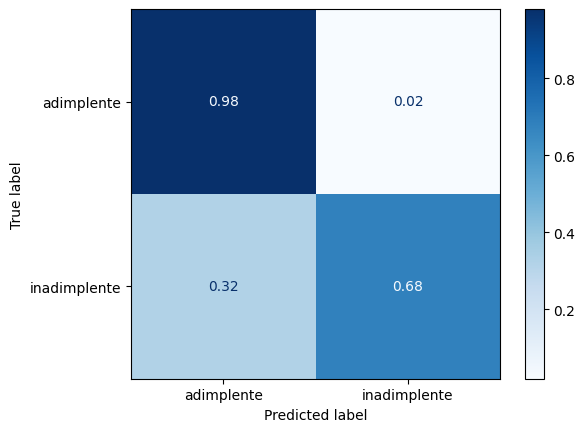

In [ ]:

ConfusionMatrixDisplay.from_estimator(
    modelo_rf, X_teste, y_teste,
    normalize='true', cmap='Blues'
);

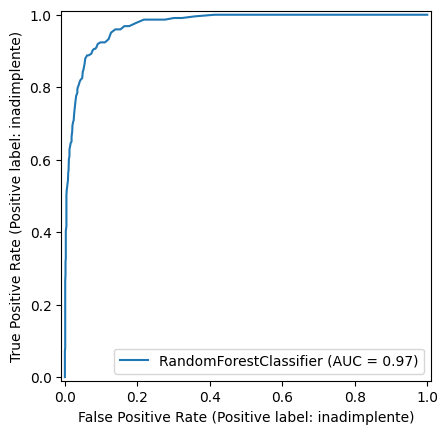

In [ ]:

RocCurveDisplay.from_estimator(
    modelo_rf, X_teste, y_teste,
    pos_label='inadimplente'
);

In [ ]:
#Vou aumentar o numero de arvores, por padrão é 100


modelo_rf_500 = RandomForestClassifier(random_state=42, n_estimators=500)

# Ajusta o classificador ao conjunto de treinamento
modelo_rf_500.fit(X_treino, y_treino)

# Prevê o Target do conjunto de teste e de treino
predicoes_rf_500_teste = modelo_rf_500.predict(X_teste)
predicoes_rf_500_treino = modelo_rf_500.predict(X_treino)

In [ ]:


acuracia_rf_500_treino = accuracy_score(y_treino, predicoes_rf_500_treino)
acuracia_rf_500_teste  = accuracy_score(y_teste, predicoes_rf_500_teste)

print(f'Acurácia no treino - Random Forest: {acuracia_rf_500_treino:.2%}')
print(f'Acurácia no teste - Random Forest:  {acuracia_rf_500_teste:.2%}')

Acurácia no treino - Random Forest: 100.00%
Acurácia no teste - Random Forest:  93.58%


In [ ]:

relatorio_rf_500 = classification_report(y_teste, predicoes_rf_500_teste)
print(relatorio_rf_500)

              precision    recall  f1-score   support

  adimplente       0.95      0.98      0.96      1194
inadimplente       0.86      0.71      0.78       223

    accuracy                           0.94      1417
   macro avg       0.90      0.84      0.87      1417
weighted avg       0.93      0.94      0.93      1417



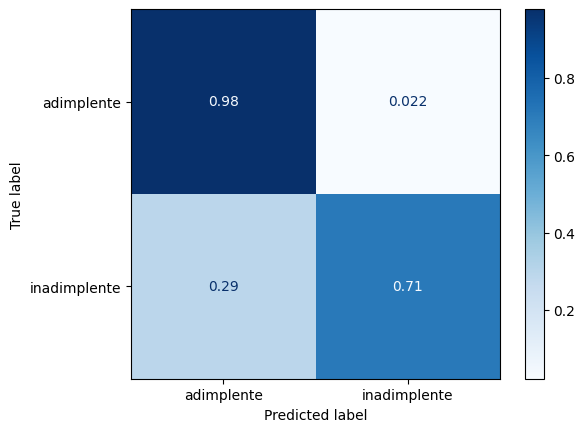

In [ ]:

ConfusionMatrixDisplay.from_estimator(
    modelo_rf_500, X_teste, y_teste,
    normalize='true', cmap='Blues'
);

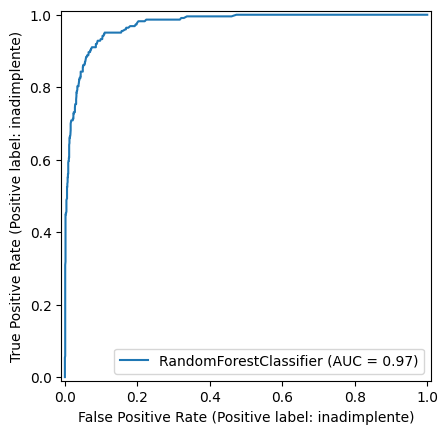

In [ ]:

RocCurveDisplay.from_estimator(
    modelo_rf_500, X_teste, y_teste,
    pos_label='inadimplente'
);

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score


In [ ]:
scorer_recall = make_scorer(recall_score, pos_label='inadimplente')

cv_estratificada = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grade_parametros = {
    'n_estimators': [200,300, 500],
    'max_depth': [None, 15],
    'criterion': ['gini', 'entropy'],
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5, 10]
}

modelo_rf_ajuste = RandomForestClassifier(random_state=42)

grid_search = GridSearchCV(
    estimator=modelo_rf_ajuste,
    param_grid=grade_parametros,
    cv=cv_estratificada,
    scoring=scorer_recall,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_treino, y_treino)

print(f"Melhores parâmetros encontrados: {grid_search.best_params_}")
print(f"Recall médio (validação cruzada): {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Melhores parâmetros encontrados: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}
Recall médio (validação cruzada): 0.7034


In [ ]:

colunas_resultado = [
    'param_max_depth',
    'param_criterion',
    'param_n_estimators',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]

resultados_cv = (
    pd.DataFrame(grid_search.cv_results_)[colunas_resultado]
    .sort_values('rank_test_score')
    .reset_index(drop=True)
)

resultados_cv

,param_max_depth,param_criterion,param_n_estimators,mean_test_score,std_test_score,rank_test_score
0,None,gini,500,0.703371,0.037164,1
1,None,gini,300,0.696629,0.030358,2
2,None,entropy,500,0.694382,0.022075,3
3,None,gini,200,0.694382,0.030482,4
4,15,gini,300,0.694382,0.010420,4
...,...,...,...,...,...,...
103,15,gini,500,0.643820,0.033445,100
104,None,gini,300,0.642697,0.034559,105
105,15,gini,300,0.640449,0.029300,106
106,15,gini,200,0.637079,0.038531,107


In [ ]:
grid_search.best_estimator_

RandomForestClassifier(n_estimators=500, random_state=42)

In [ ]:

modelo_rf_ajustado = grid_search.best_estimator_

predicoes_rf_ajustado = modelo_rf_ajustado.predict(X_teste)
predicoes_rf_treino_ajustado = modelo_rf_ajustado.predict(X_treino)

In [ ]:

acuracia_rf_treino_ajustado = accuracy_score(y_treino, predicoes_rf_treino_ajustado)
acuracia_rf_teste_ajustado  = accuracy_score(y_teste, predicoes_rf_ajustado)

print(f'Acurácia no treino: {acuracia_rf_treino_ajustado:.2%}')
print(f'Acurácia no teste:  {acuracia_rf_teste_ajustado:.2%}')

Acurácia no treino: 100.00%
Acurácia no teste:  93.58%


In [ ]:
print(classification_report(y_teste, predicoes_rf_ajustado))

              precision    recall  f1-score   support

  adimplente       0.95      0.98      0.96      1194
inadimplente       0.86      0.71      0.78       223

    accuracy                           0.94      1417
   macro avg       0.90      0.84      0.87      1417
weighted avg       0.93      0.94      0.93      1417



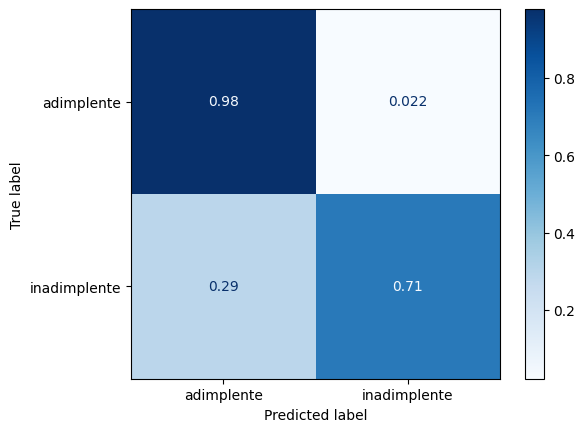

In [ ]:

ConfusionMatrixDisplay.from_estimator(
    modelo_rf_ajustado, X_teste, y_teste,
    normalize='true', cmap='Blues'
);

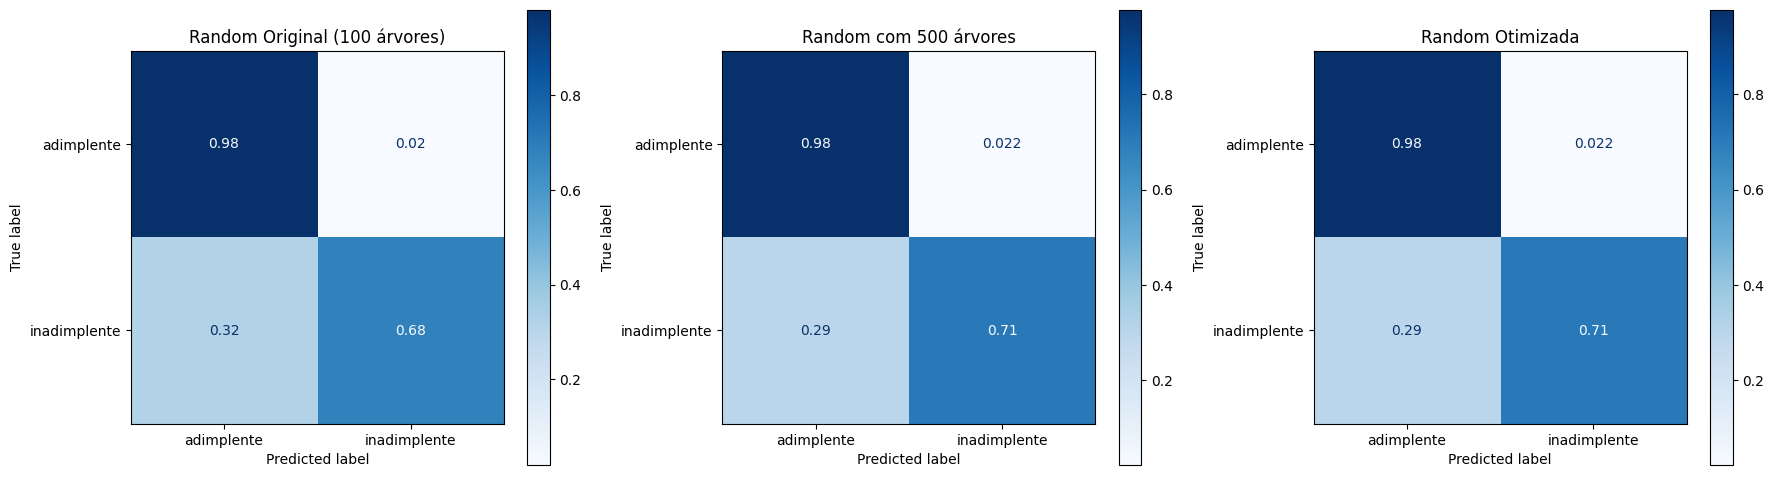

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_estimator(
    modelo_rf,
    X_teste,
    y_teste,
    normalize='true',
    cmap='Blues',
    ax=ax[0]
)
ax[0].set_title('Random Original (100 árvores)')

ConfusionMatrixDisplay.from_estimator(
    modelo_rf_500,
    X_teste,
    y_teste,
    normalize='true',
    cmap='Blues',
    ax=ax[1]
)
ax[1].set_title('Random com 500 árvores')

ConfusionMatrixDisplay.from_estimator(
    modelo_rf_ajustado,
    X_teste,
    y_teste,
    normalize='true',
    cmap='Blues',
    ax=ax[2]
)
ax[2].set_title('Random Otimizada')

plt.tight_layout()
plt.show()

In [ ]:
modelos_rf = {
    'RF original (100 árvores)': modelo_rf,
    'RF com 500 árvores': modelo_rf_500,
    'RF otimizado': modelo_rf_ajustado
}

resultados_rf = []

for nome, modelo in modelos_rf.items():
    previsoes_treino = modelo.predict(X_treino)
    previsoes_teste = modelo.predict(X_teste)

    resultados_rf.append({
        'Modelo': nome,
        'Acurácia treino': accuracy_score(y_treino, previsoes_treino),
        'Acurácia teste': accuracy_score(y_teste, previsoes_teste),
        'Precisão inadimplentes': precision_score(y_teste, previsoes_teste, pos_label='inadimplente'),
        'Recall inadimplentes': recall_score(y_teste, previsoes_teste, pos_label='inadimplente'),
        'F1 inadimplentes': f1_score(y_teste, previsoes_teste, pos_label='inadimplente')
    })

tabela_rf = pd.DataFrame(resultados_rf).set_index('Modelo')

display(tabela_rf.style.format('{:.2%}'))

,Acurácia treino,Acurácia teste,Precisão inadimplentes,Recall inadimplentes,F1 inadimplentes
Modelo,,,,,
RF original (100 árvores),100.00%,93.23%,86.29%,67.71%,75.88%
RF com 500 árvores,100.00%,93.58%,85.87%,70.85%,77.64%
RF otimizado,100.00%,93.58%,85.87%,70.85%,77.64%


### Conclusão

Neste projeto, avaliamos o desempenho do algoritmo Random Forest na classificação de clientes adimplentes e inadimplentes, considerando diferentes configurações e utilizando métricas de avaliação tanto no conjunto de treinamento quanto no conjunto de teste.

Inicialmente, o modelo com 100 árvores apresentou acurácia de 93,23% no conjunto de teste e recall de 67,71% para os clientes inadimplentes. Ao aumentar o número de árvores para 500, observamos uma melhoria modesta, com acurácia de 93,58% e recall de 70,85%.

Posteriormente, utilizamos o `GridSearchCV` com validação cruzada estratificada de cinco partições, adotando o recall dos inadimplentes como critério de otimização. O procedimento selecionou uma configuração com 500 árvores, critério Gini, profundidade sem limite explícito (`max_depth=None`), `min_samples_leaf=1` e `min_samples_split=2`, alcançando recall médio de 70,34% na validação cruzada.

O modelo otimizado apresentou resultados equivalentes aos do Random Forest com 500 árvores, indicando que a busca de hiperparâmetros não proporcionou ganhos adicionais dentro das configurações avaliadas.

Um aspecto relevante foi a diferença entre o desempenho nos conjuntos de treinamento e teste. Todos os modelos apresentaram acurácia de 100% no treinamento, enquanto a acurácia no teste permaneceu entre 93,23% e 93,58%. Essa diferença indica um possível ajuste excessivo às particularidades dos dados de treinamento. Entretanto, a acurácia relativamente elevada no teste demonstra que os modelos também conseguiram identificar padrões úteis em observações não utilizadas durante o treinamento.

Por fim, embora o Random Forest tenha apresentado bons resultados gerais de classificação, o recall dos inadimplentes permaneceu próximo de 71%. Isso significa que aproximadamente 29% dos clientes efetivamente inadimplentes não foram identificados pelo modelo, uma limitação importante em aplicações de análise de risco de crédito.

Portanto, os resultados mostram que o aumento do número de árvores e a otimização dos hiperparâmetros proporcionaram ganhos limitados. A escolha do modelo mais adequado deve considerar não apenas a acurácia, mas também a capacidade de identificar inadimplentes e os custos associados aos diferentes tipos de erro de classificação.

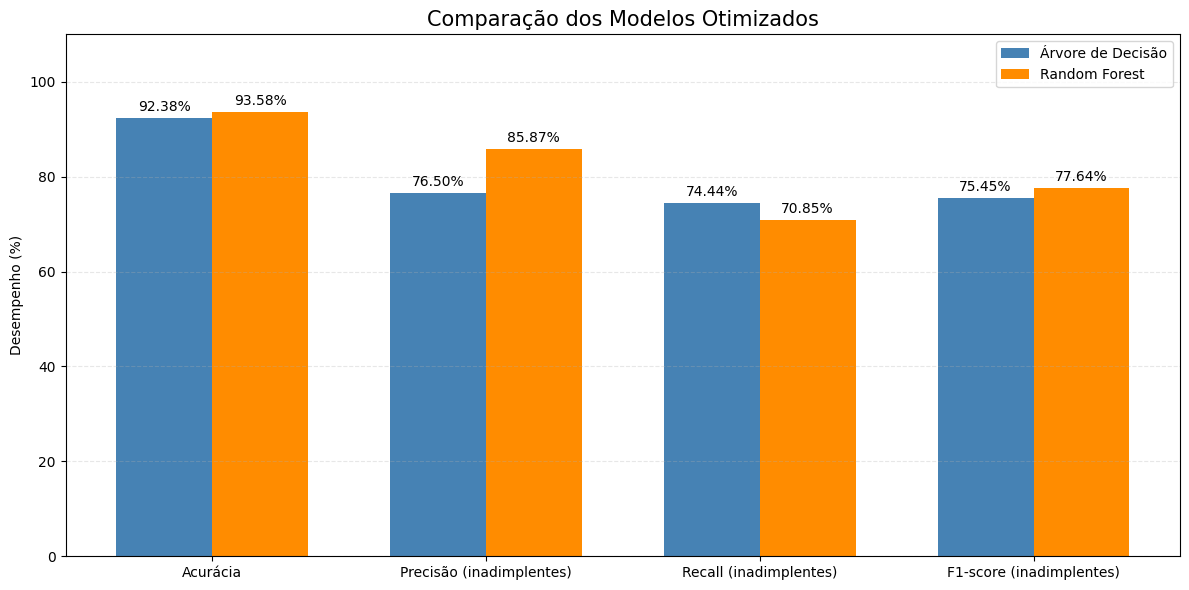

In [111]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Resultados dos modelos otimizados no conjunto de teste
resultados = pd.DataFrame({
    'Métrica': [
        'Acurácia',
        'Precisão (inadimplentes)',
        'Recall (inadimplentes)',
        'F1-score (inadimplentes)'
    ],
    'Árvore de Decisão': [92.38, 76.50, 74.44, 75.45],
    'Random Forest': [93.58, 85.87, 70.85, 77.64]
})

# Posições das barras
x = np.arange(len(resultados))
largura = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

barras_arvore = ax.bar(
    x - largura/2,
    resultados['Árvore de Decisão'],
    largura,
    label='Árvore de Decisão',
    color='steelblue'
)

barras_rf = ax.bar(
    x + largura/2,
    resultados['Random Forest'],
    largura,
    label='Random Forest',
    color='darkorange'
)

# Exibir os valores sobre as barras
ax.bar_label(barras_arvore, fmt='%.2f%%', padding=3)
ax.bar_label(barras_rf, fmt='%.2f%%', padding=3)

# Personalização
ax.set_title('Comparação dos Modelos Otimizados', fontsize=15)
ax.set_ylabel('Desempenho (%)')
ax.set_xticks(x)
ax.set_xticklabels(resultados['Métrica'])
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

### Comparação entre a árvore de decisão única e o Random Forest

Após o treinamento, a avaliação e a otimização dos dois algoritmos, comparamos os modelos selecionados pelo `GridSearchCV`, utilizando como critério prioritário o recall dos clientes inadimplentes.

A árvore de decisão única otimizada apresentou acurácia de 92,38% no conjunto de teste, enquanto o Random Forest alcançou 93,58%. O Random Forest também apresentou maior precisão na classificação dos inadimplentes, aproximadamente 86%, contra 76,50% da árvore única. Isso indica que, entre os clientes classificados como inadimplentes, uma proporção maior realmente pertencia a essa classe nas previsões do Random Forest.

Entretanto, ao analisarmos o recall, observamos um resultado diferente. A árvore de decisão única identificou 74,44% dos clientes efetivamente inadimplentes, enquanto o Random Forest identificou 70,85%. Portanto, apesar da maior complexidade do Random Forest e de sua acurácia superior, a árvore única apresentou melhor desempenho na métrica estabelecida como prioridade.

Em relação ao ajuste aos dados de treinamento, o Random Forest apresentou acurácia de 100%, contra 97,26% da árvore única. A diferença entre as acurácias de treinamento e teste foi de 6,42 pontos percentuais no Random Forest e 4,88 pontos percentuais na árvore única. Esses resultados sugerem maior ajuste do Random Forest aos dados de treinamento, embora essa diferença, isoladamente, não permita concluir que sua capacidade de generalização seja inferior, considerando seu desempenho no conjunto de teste.

Os resultados também evidenciam um trade-off entre precisão e recall. O Random Forest apresentou menor proporção de falsos positivos entre os clientes classificados como inadimplentes, enquanto a árvore única conseguiu identificar uma parcela maior dos inadimplentes reais, ao custo de produzir mais falsos alarmes.

Dessa forma, não foi possível estabelecer a superioridade absoluta de um algoritmo sobre o outro. A escolha depende dos objetivos da aplicação e dos custos associados aos erros de classificação. Considerando especificamente a prioridade estabelecida neste projeto, de identificar a maior proporção possível de clientes inadimplentes, a árvore de decisão única otimizada apresentou o resultado mais favorável em termos de recall.

Por fim, os experimentos demonstram que o aumento da complexidade do modelo não garante melhoria em todas as métricas de classificação. Como possíveis extensões, destacam-se a avaliação dos custos de falsos positivos e falsos negativos, o ajuste do limiar de classificação e a comparação com outros algoritmos supervisionados.